# WattIf : analyse exploratoire
Décomposition, autocorrélations et tests de stationnarité sur la consommation journalière.
Les tests sont faits sur l'échantillon d'apprentissage uniquement (pas de fuite d'information du test).

In [1]:
# CELLULE 2 : IMPORTS, CHARGEMENT ET SPLIT TRAIN/TEST

# --- Librairies ---
import numpy as np                      # calcul numérique
import pandas as pd                     # manipulation des tableaux et des dates
import matplotlib.pyplot as plt         # graphiques
import statsmodels                      # économétrie / séries temporelles
from statsmodels.tsa.seasonal import STL, MSTL                       # décompositions saisonnières
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf        # autocorrélogrammes
from statsmodels.tsa.stattools import adfuller, kpss                 # tests de stationnarité

# --- Reproductibilité ---
np.random.seed(42)                      # même résultat à chaque exécution
print("statsmodels", statsmodels.__version__)   # version documentée pour le rapport

# --- Dossier de sortie des figures (créé s'il n'existe pas) ---
import os
os.makedirs("figures", exist_ok=True)   # exist_ok=True : pas d'erreur s'il existe déjà

# --- Chargement du jeu préparé dans 01_preparation_donnees ---
df = pd.read_csv("data/daily.csv", index_col="date", parse_dates=True)
df = df.asfreq("D")                     # fréquence journalière explicite

# --- Split chronologique 90/10 (identique pour tout le groupe) ---
n_train = int(len(df) * 0.9)            # 3506 jours d'apprentissage
train, test = df.iloc[:n_train], df.iloc[n_train:]
y = train["conso_gwh"]                  # série étudiée : on n'analyse QUE le train

print(train.index[0].date(), "→", train.index[-1].date(), len(train))
print(test.index[0].date(), "→", test.index[-1].date(), len(test))

statsmodels 0.15.0
2016-01-01 → 2025-08-06 3506
2025-08-07 → 2026-08-31 390


## 1. Décomposition de la série
La consommation a deux saisonnalités : hebdomadaire (7 jours, effet week-end)
et annuelle (365 jours, effet chauffage). STL n'en gère qu'une à la fois,
on utilise donc MSTL (Multiple STL) qui les extrait toutes les deux.

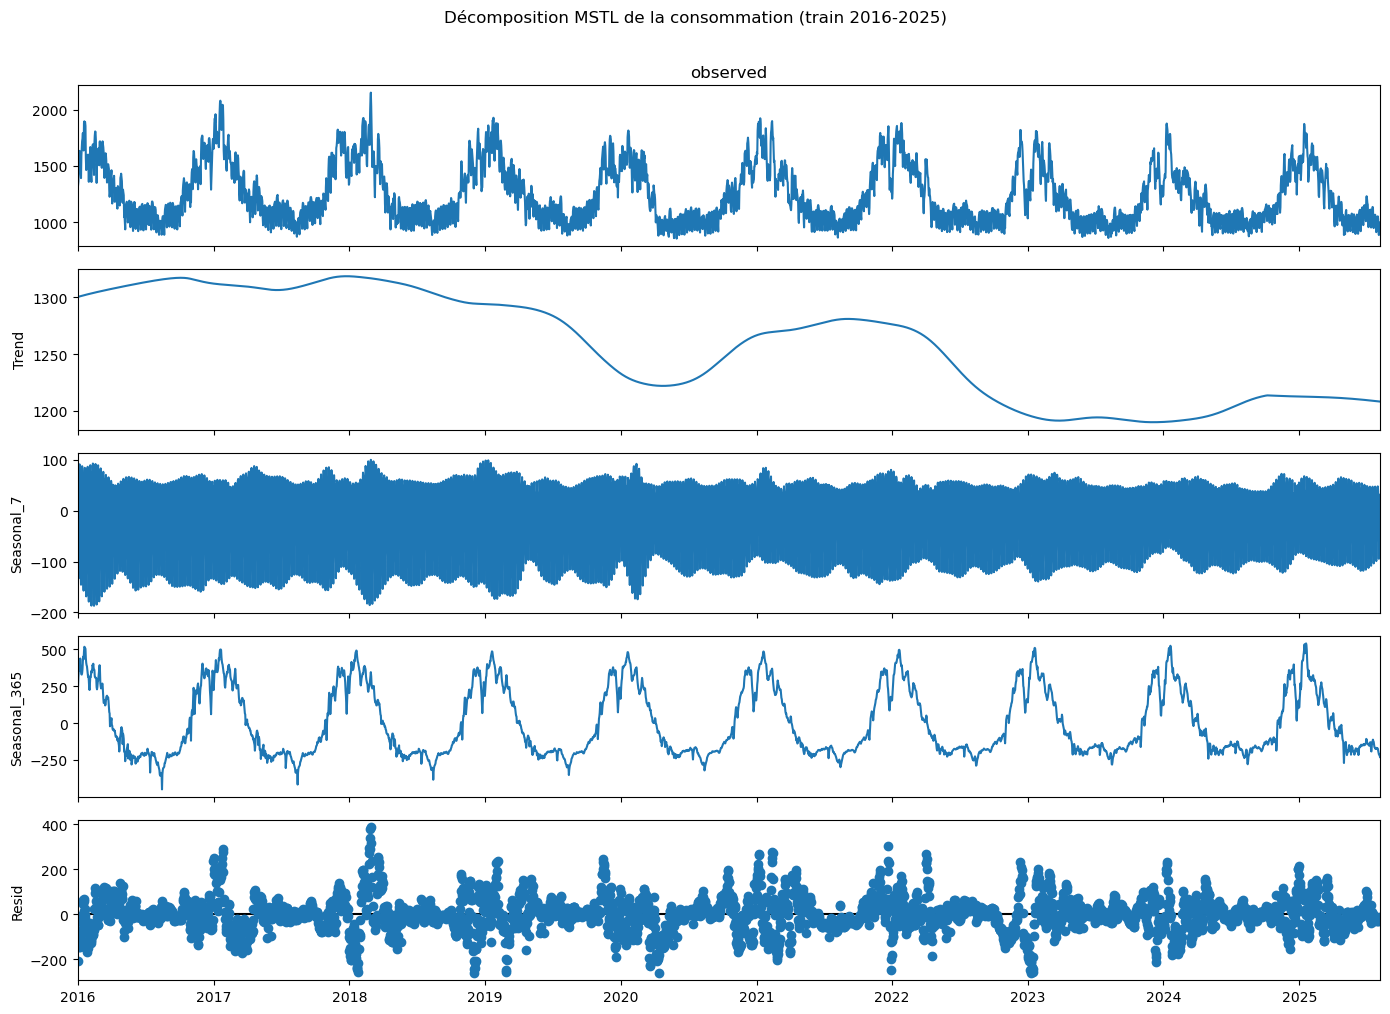

Force de seasonal_7 : 0.45
Force de seasonal_365 : 0.90


In [2]:
# CELLULE 4 : DÉCOMPOSITION MSTL (TENDANCE + 2 SAISONNALITÉS)

# --- Décomposition : y = tendance + saison_7 + saison_365 + résidu ---
mstl = MSTL(y, periods=(7, 365))        # 7 = semaine, 365 = année
res = mstl.fit()                        # peut prendre ~10 secondes

# --- Graphique des composantes ---
fig = res.plot()
fig.set_size_inches(14, 10)
fig.suptitle("Décomposition MSTL de la consommation (train 2016-2025)", y=1.01)
plt.tight_layout()
plt.savefig("figures/mstl.png", dpi=150, bbox_inches="tight")   # figure pour le rapport
plt.show()

# --- Force de chaque saisonnalité (0 = absente, 1 = dominante) ---
# formule de Hyndman : 1 - Var(résidu) / Var(saison + résidu)
for col in res.seasonal.columns:
    force = 1 - res.resid.var() / (res.seasonal[col] + res.resid).var()
    print(f"Force de {col} : {force:.2f}")

### Interprétation de la décomposition
La saisonnalité annuelle domine (force 0,90) : la consommation suit le cycle de chauffage,
avec un écart d'environ ±400 GWh/jour entre l'hiver et l'été. La saisonnalité hebdomadaire
est nette mais plus modérée (force 0,45, environ ±100 GWh/jour, consommation plus basse le week-end).
La tendance met en évidence deux ruptures : une baisse en 2020 (confinements) suivie d'un
rebond en 2021, puis une chute durable fin 2022 (crise énergétique et plan de sobriété),
d'environ 1 310 à 1 200 GWh/jour, sans retour au niveau d'avant-crise.
Ces deux ruptures sont l'objet de l'analyse contrefactuelle.

## 2. Autocorrélations (ACF / PACF)
On regarde la série brute, puis différenciée, pour identifier :
- la saisonnalité hebdomadaire (pics aux retards 7, 14, 21…)
- la non-stationnarité (décroissance très lente de l'ACF)
- des pistes d'ordres p, q, P, Q pour le SARIMA de la section 3.1.

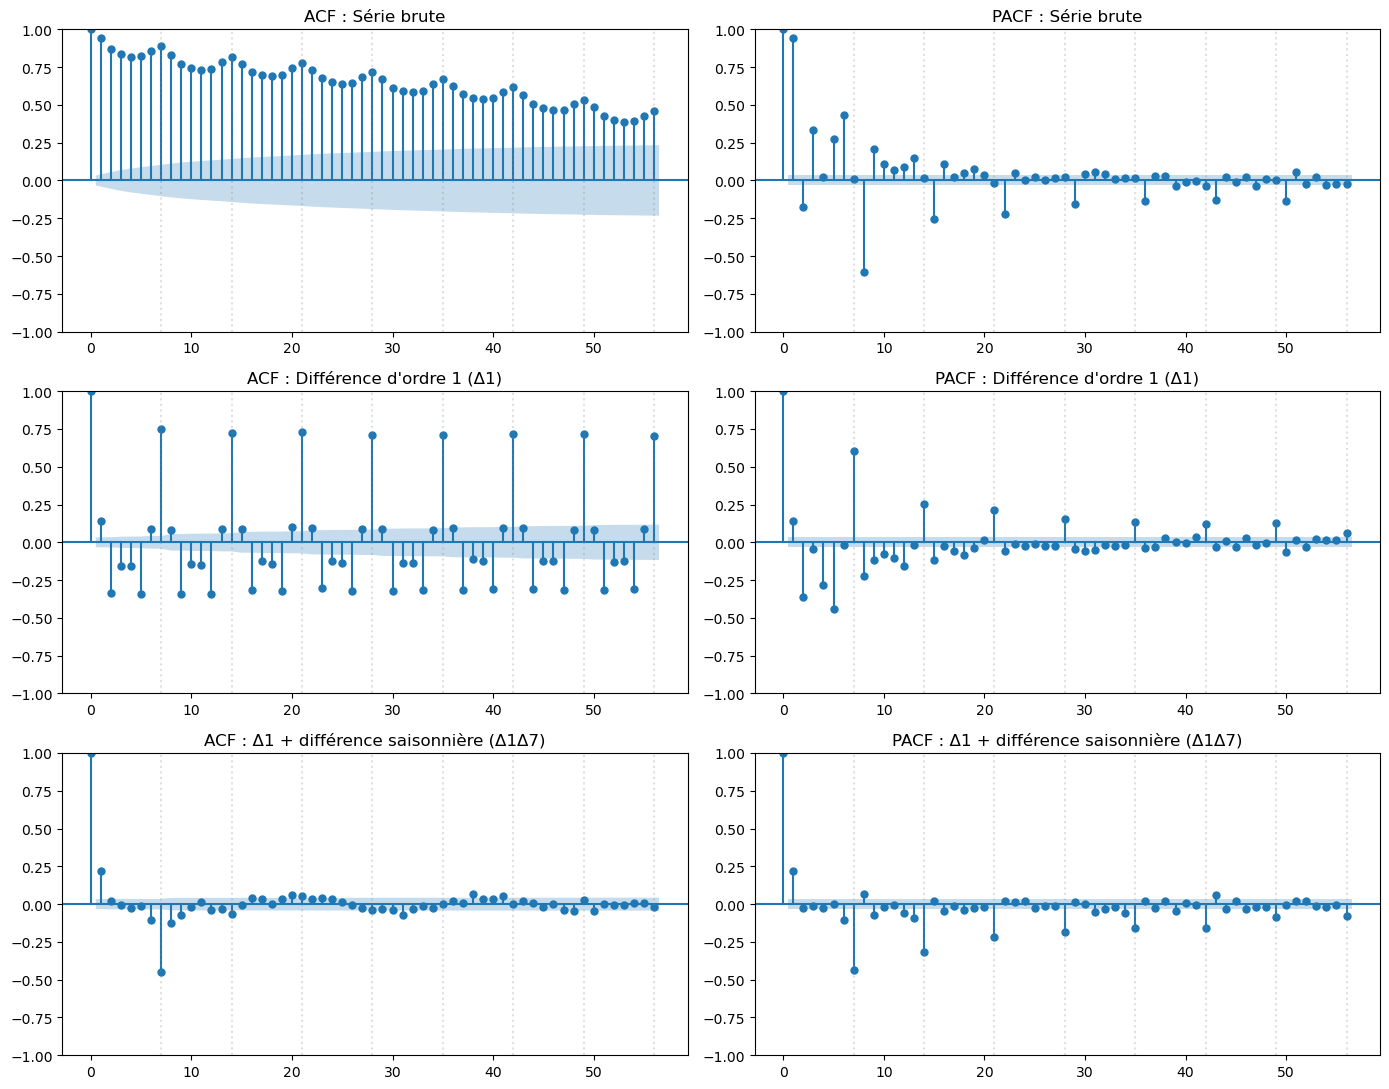

In [3]:
# CELLULE 6 : AUTOCORRÉLATIONS ACF / PACF (BRUTE ET DIFFÉRENCIÉES)

# --- Trois versions de la série ---
series = {
    "Série brute": y,
    "Différence d'ordre 1 (Δ1)": y.diff(1).dropna(),               # retire la tendance
    "Δ1 + différence saisonnière (Δ1Δ7)": y.diff(1).diff(7).dropna(), # retire aussi la semaine
}

# --- Une ligne par série : ACF à gauche, PACF à droite ---
fig, axes = plt.subplots(3, 2, figsize=(14, 11))
for i, (nom, s) in enumerate(series.items()):
    plot_acf(s, lags=56, ax=axes[i, 0], title=f"ACF : {nom}")     # 56 retards = 8 semaines
    plot_pacf(s, lags=56, ax=axes[i, 1], title=f"PACF : {nom}", method="ywm")
    for ax in axes[i]:
        for k in range(7, 57, 7):                                  # repères verticaux tous les 7 jours
            ax.axvline(k, color="grey", alpha=0.25, linestyle=":")

plt.tight_layout()
plt.savefig("figures/acf_pacf.png", dpi=150, bbox_inches="tight")  # figure pour le rapport
plt.show()

### Interprétation des ACF / PACF

**Série brute.** L'ACF décroît très lentement (encore ≈ 0,45 au retard 56) avec des bosses
tous les 7 jours : la série n'est pas stationnaire et présente une saisonnalité hebdomadaire.
La PACF montre un pic très fort au retard 1 (≈ 0,95) puis des pics significatifs autour du retard 7–8.

**Après une différence simple (Δ1).** La tendance disparaît, mais l'ACF présente des pics
élevés (≈ 0,7) aux retards 7, 14, 21, … 56 qui ne décroissent pas : il reste une
non-stationnarité saisonnière de période 7. Une différence saisonnière (D = 1, s = 7) est nécessaire.

**Après Δ1 et Δ7.** L'ACF retombe immédiatement dans l'intervalle de confiance, sauf :
- un pic positif au retard 1 (≈ 0,2) → composante non saisonnière d'ordre 1 (AR(1) ou MA(1)) ;
- un pic négatif au retard 7 (≈ −0,45) puis plus rien → MA saisonnier d'ordre 1 (Q = 1).
La PACF décroît aux retards saisonniers 7, 14, 21, ce qui confirme une composante MA saisonnière.

**Pistes pour le SARIMA** (à départager par AIC/BIC et diagnostics des résidus) :
SARIMA(0,1,1)(0,1,1)₇ (modèle « airline »), SARIMA(1,1,1)(0,1,1)₇, SARIMA(1,1,0)(0,1,1)₇.

**Limite.** La saisonnalité annuelle (365 jours) n'est pas captée par s = 7.
Elle devra être prise en compte par des variables exogènes (température, hdd/cdd) ou des termes de Fourier.

## 3. Tests de stationnarité (ADF et KPSS)
Les deux tests ont des hypothèses opposées, on les utilise ensemble :
- ADF : H0 = racine unitaire (non stationnaire). p < 0,05 → stationnaire.
- KPSS : H0 = stationnaire. p < 0,05 → non stationnaire.
Série jugée stationnaire si ADF rejette ET KPSS ne rejette pas.

In [4]:
# CELLULE 9 : TESTS ADF ET KPSS SUR LES TROIS VERSIONS DE LA SÉRIE

import warnings

resultats = []
for nom, s in series.items():                          # mêmes séries que la cellule 6
    with warnings.catch_warnings():                    # masque les avertissements de version / table
        warnings.simplefilter("ignore")
        adf_stat, adf_p, *_ = adfuller(s, autolag="AIC")              # retards choisis par AIC
        kpss_stat, kpss_p, *_ = kpss(s, regression="c", nlags="auto")
    stationnaire = (adf_p < 0.05) and (kpss_p > 0.05)  # règle de décision combinée
    resultats.append({
        "Série": nom,
        "ADF stat": round(adf_stat, 3), "ADF p-value": round(adf_p, 4),
        "KPSS stat": round(kpss_stat, 3), "KPSS p-value": round(kpss_p, 4),
        "Conclusion": "stationnaire" if stationnaire else "non stationnaire",
    })

tableau_tests = pd.DataFrame(resultats).set_index("Série")
tableau_tests.to_csv("figures/tests_stationnarite.csv")   # tableau pour le rapport
tableau_tests

,ADF stat,ADF p-value,KPSS stat,KPSS p-value,Conclusion
Série,,,,,
Série brute,-4.101,0.001,0.403,0.0759,stationnaire
Différence d'ordre 1 (Δ1),-12.207,0.000,0.016,0.1000,stationnaire
Δ1 + différence saisonnière (Δ1Δ7),-18.398,0.000,0.007,0.1000,stationnaire


### Interprétation des tests de stationnarité

Série brute : l'ADF rejette la racine unitaire (p = 0,001) ; le KPSS ne rejette pas la
stationnarité à 5 % (p = 0,076) mais la rejette à 10 % (stat 0,403 > 0,347).
Les tests concluent donc à une stationnarité « limite », ce qui contraste avec l'ACF à
décroissance lente. Cette lenteur s'explique par le cycle annuel, régulier et récurrent
(la série revient vers son niveau moyen chaque année), plutôt que par une racine unitaire.

Les tests ADF/KPSS ne détectent pas la non-stationnarité saisonnière : l'ACF de Δ1 garde des
pics non décroissants aux retards 7, 14, 21…, ce qui justifie une différence saisonnière.
Après Δ1Δ7, l'ACF au retard 1 est positive (+0,2), donc pas de sur-différenciation ;
le pic à −0,45 au retard 7 suggère cependant une saisonnalité hebdomadaire partiellement
déterministe.

Décision retenue : d = 1, D = 1, s = 7 (choix prudent, justifié par la limite KPSS à 10 %,
l'ACF lente et les ruptures de tendance de 2020 et 2022).
Alternative à comparer : d = 1, D = 0 avec le jour de la semaine en variable exogène.

In [5]:
# CELLULE 11 : NOMBRE DE DIFFÉRENCIATIONS RECOMMANDÉ (pmdarima)

# si erreur d'import : %pip install pmdarima, puis redémarrer le kernel
from pmdarima.arima import ndiffs, nsdiffs

print("d recommandé (KPSS) :", ndiffs(y, test="kpss"))
print("d recommandé (ADF)  :", ndiffs(y, test="adf"))
print("D recommandé (OCSB, s = 7) :", nsdiffs(y, m=7, test="ocsb"))
print("D recommandé (CH,   s = 7) :", nsdiffs(y, m=7, test="ch"))

d recommandé (KPSS) : 1
d recommandé (ADF)  : 0
D recommandé (OCSB, s = 7) : 0
D recommandé (CH,   s = 7) : 1


### Conclusion sur l'ordre de différenciation
Les tests automatiques divergent : ndiffs recommande d = 1 (KPSS) ou d = 0 (ADF) ;
nsdiffs recommande D = 0 (OCSB) ou D = 1 (Canova-Hansen). La série se situe à la frontière
entre saisonnalité déterministe et stochastique, ce que confirmaient déjà le KPSS limite
et le pic à −0,45 au retard 7 après Δ1Δ7.
Nous retenons d = 1 (critère KPSS, plus conservateur, et ruptures de tendance) et
comparons deux spécifications sur les critères AIC/BIC et l'erreur hors échantillon :
(A) d = 1, D = 1, s = 7 ;  (B) d = 1, D = 0 avec le jour de la semaine en exogène.

## 4. Valeurs aberrantes
On cherche les jours anormaux dans le résidu de la décomposition MSTL (ce qui reste une fois
la tendance et les deux saisonnalités retirées). Critère robuste : score z modifié
basé sur la médiane et la MAD, seuil |z| > 3,5 (Iglewicz et Hoaglin).
La MAD est préférée à l'écart-type car elle n'est pas gonflée par les valeurs extrêmes elles-mêmes.

Jours aberrants : 133 (3.8% du train)

Répartition par mois :
{1: 53, 2: 24, 3: 10, 4: 14, 10: 2, 11: 8, 12: 22}

10 plus fortes SOUS-consommations :
            conso_gwh  residu_gwh  score_z  temp_moy  ferie
date                                                       
2020-04-13      906.0      -262.0     -5.0      13.5      1
2023-01-11     1414.0      -261.0     -5.0       9.3      0
2018-01-24     1529.0      -257.0     -4.9      10.8      0
2018-12-04     1437.0      -260.0     -4.9      11.2      0
2019-02-28     1419.0      -258.0     -4.9      10.1      0
2023-01-14     1283.0      -257.0     -4.9       9.3      0
2018-12-03     1412.0      -246.0     -4.7      12.9      0
2019-02-27     1411.0      -248.0     -4.7      11.5      0
2021-12-30     1268.0      -250.0     -4.7      13.3      0
2023-01-08     1193.0      -246.0     -4.7       9.5      0

10 plus fortes SUR-consommations :
            conso_gwh  residu_gwh  score_z  temp_moy  ferie
date                              

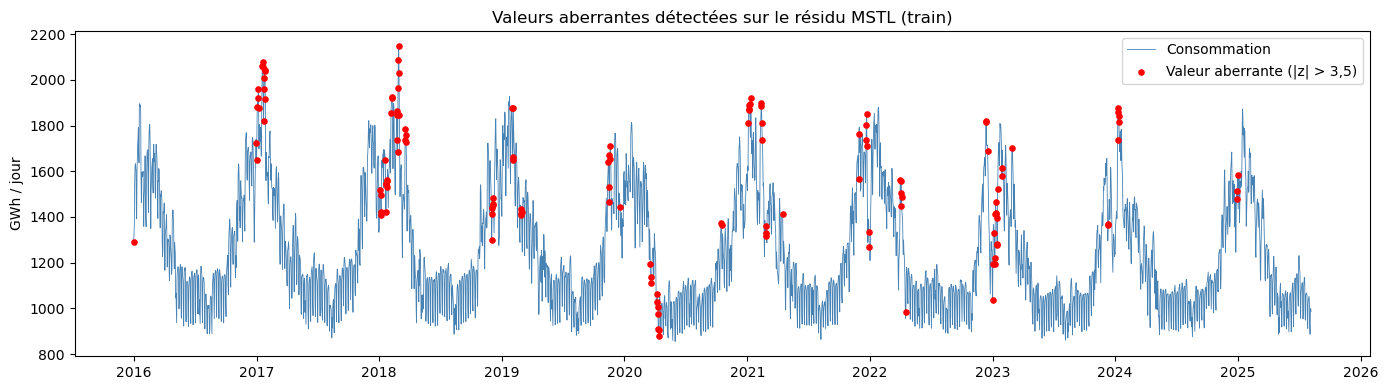

In [6]:
# CELLULE 13 : DÉTECTION DES VALEURS ABERRANTES SUR LE RÉSIDU MSTL

# --- Score z robuste : (x - médiane) / MAD ---
residu = res.resid                                         # résidu de la cellule 4 (MSTL)
mad = (residu - residu.median()).abs().median()            # écart absolu médian
z = 0.6745 * (residu - residu.median()) / mad              # 0,6745 : mise à l'échelle sur une loi normale
aberrants = z[z.abs() > 3.5]                               # seuil d'Iglewicz-Hoaglin
print(f"Jours aberrants : {len(aberrants)} ({len(aberrants) / len(y):.1%} du train)")

# --- Tableau descriptif des jours détectés ---
tab_aberrants = pd.DataFrame({
    "conso_gwh": y[aberrants.index].round(0),
    "residu_gwh": residu[aberrants.index].round(0),
    "score_z": aberrants.round(1),
    "temp_moy": train.loc[aberrants.index, "temp_moy"].round(1),
    "ferie": train.loc[aberrants.index, "ferie"],
})
print("\nRépartition par mois :")
print(tab_aberrants.index.month.value_counts().sort_index().to_dict())
print("\n10 plus fortes SOUS-consommations :")
print(tab_aberrants.nsmallest(10, "score_z").to_string())
print("\n10 plus fortes SUR-consommations :")
print(tab_aberrants.nlargest(10, "score_z").to_string())

# --- Graphique : la série avec les jours aberrants en rouge ---
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(y.index, y, lw=0.6, color="steelblue", label="Consommation")
ax.scatter(aberrants.index, y[aberrants.index], color="red", s=14, zorder=3, label="Valeur aberrante (|z| > 3,5)")
ax.set_title("Valeurs aberrantes détectées sur le résidu MSTL (train)")
ax.set_ylabel("GWh / jour")
ax.legend()
plt.tight_layout()
plt.savefig("figures/valeurs_aberrantes.png", dpi=150, bbox_inches="tight")
plt.show()

### Interprétation
133 jours (3,8 %) dépassent le seuil. Ce ne sont **pas des erreurs de mesure** : ils sont presque
tous expliqués par des événements identifiables :
- **sur-consommations** = vagues de froid (fin février 2018 « Moscou-Paris » avec un record de
  2 150 GWh le 28/02 par −3 °C, janvier 2017, janvier 2021, décembre 2022) ;
- **sous-consommations** = premier confinement (mars-avril 2020), jours fériés (lundi de Pâques 2020),
  hiver doux et sobriété (janvier 2023).
Ils sont concentrés en hiver, quand la sensibilité à la température est maximale : la MSTL ne
voit pas la température, donc tout écart météo se retrouve dans le résidu.
**Décision : on les conserve.** Les supprimer ferait disparaître les chocs que l'on veut justement
modéliser. Ils seront expliqués par les variables exogènes (hdd, cdd, ferie) dans les modèles.

## 5. Relation consommation / température
La relation attendue est en U : la consommation augmente quand il fait froid (chauffage)
et, plus faiblement, quand il fait chaud (climatisation). On vérifie la forme et les seuils.

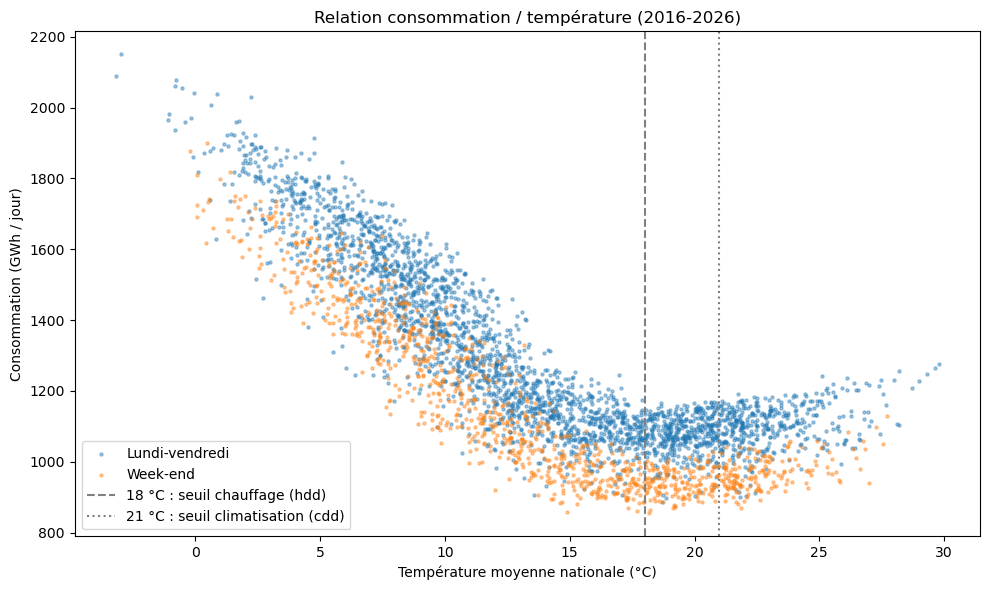

          count    mean
temp_moy               
(-5, 5]     329  1720.0
(5, 10]     983  1473.0
(10, 15]    990  1206.0
(15, 18]    479  1051.0
(18, 21]    556  1041.0
(21, 24]    411  1052.0
(24, 30]    148  1104.0

Pente sous 15 °C : -56.2 GWh/jour par °C
conso_gwh    1.000
temp_moy    -0.828
hdd          0.893
cdd         -0.204
Name: conso_gwh, dtype: float64


In [7]:
# CELLULE 16 : NUAGE CONSOMMATION / TEMPÉRATURE ET COURBE EN U

# --- Nuage de points, semaine vs week-end ---
semaine = df["jour_semaine"] < 5                            # lundi = 0 ... vendredi = 4
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(df.loc[semaine, "temp_moy"], df.loc[semaine, "conso_gwh"], s=5, alpha=0.4, label="Lundi-vendredi")
ax.scatter(df.loc[~semaine, "temp_moy"], df.loc[~semaine, "conso_gwh"], s=5, alpha=0.4, label="Week-end")
ax.axvline(18, color="grey", ls="--", label="18 °C : seuil chauffage (hdd)")
ax.axvline(21, color="grey", ls=":", label="21 °C : seuil climatisation (cdd)")
ax.set_xlabel("Température moyenne nationale (°C)")
ax.set_ylabel("Consommation (GWh / jour)")
ax.set_title("Relation consommation / température (2016-2026)")
ax.legend()
plt.tight_layout()
plt.savefig("figures/conso_vs_temperature.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Consommation moyenne par tranche de température ---
tranches = pd.cut(df["temp_moy"], bins=[-5, 5, 10, 15, 18, 21, 24, 30])
print(df.groupby(tranches, observed=True)["conso_gwh"].agg(["count", "mean"]).round(0))

# --- Pente côté froid : GWh supplémentaires par degré en moins ---
froid = df["temp_moy"] < 15
pente = np.polyfit(df.loc[froid, "temp_moy"], df.loc[froid, "conso_gwh"], 1)[0]
print(f"\nPente sous 15 °C : {pente:.1f} GWh/jour par °C")

# --- Corrélations avec la consommation ---
print(df[["conso_gwh", "temp_moy", "hdd", "cdd"]].corr()["conso_gwh"].round(3))

### Interprétation
La relation est bien en U, mais très asymétrique. Côté froid, chaque degré en moins sous
15 °C ajoute environ 56 GWh/jour (≈ +2,3 GW de puissance moyenne) : c'est le chauffage
électrique, très répandu en France. Côté chaud, la remontée est faible
(≈ +60 GWh/jour entre 18-21 °C et plus de 24 °C) : la climatisation reste peu développée.
Le minimum est atteint vers 18-21 °C, ce qui valide les seuils retenus pour hdd et cdd.
Les degrés-jours de chauffage linéarisent la relation : la corrélation passe de −0,83
(température brute) à 0,89 (hdd). Enfin, les week-ends forment un nuage décalé vers le bas
à température égale, ce qui confirme l'intérêt d'une variable jour de la semaine.